In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import keras
from keras.datasets import mnist
from keras.models import Sequential
from keras.layers import Dense
from keras.optimizers import Adam
from keras.utils import to_categorical
import random

In [ ]:
np.random.seed(0)

In [ ]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(60000, 28, 28)
(10000, 28, 28)
(60000,)
(10000,)


In [ ]:
assert(X_train.shape[0] == y_train.shape[0]), "The number of image is not equal to the number of labels."
assert(X_test.shape[0] == y_test.shape[0]), "The number of image is not equal to the number of labels."
assert(X_train.shape[1:] == (28, 28)), "The dimension of the image is not 28 x 28"
assert(X_test.shape[1:] == (28, 28)), "The dimension of the image is not 28 x 28"

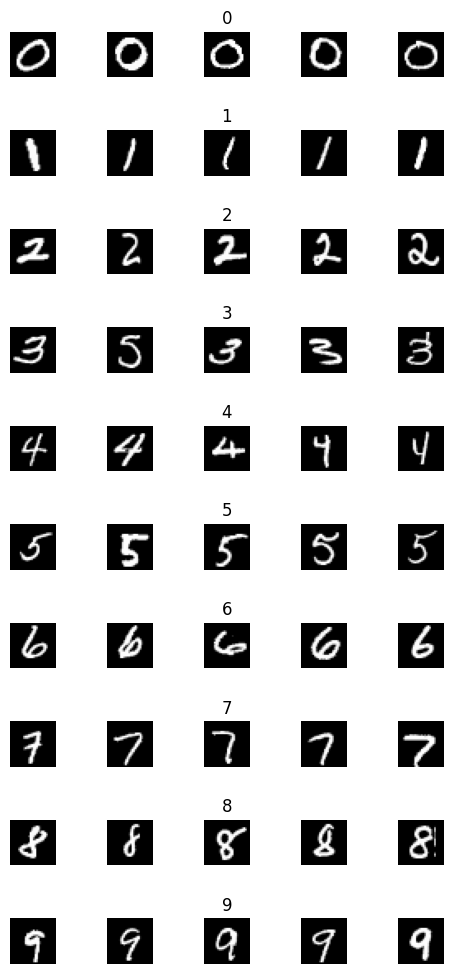

In [ ]:
# Lista para guardar a quantidade de amostras de cada classe
num_of_samples = []

cols = 5 # Número de colunas (amostras por dígito)
num_classes = 10 # Número de linhas (uma para cada dígito de 0 a 9)

# Cria uma grade de subplots com 10 linhas e 5 colunas
fig, axs = plt.subplots(nrows=num_classes, ncols=cols, figsize=(5, 10))
fig.tight_layout() # Ajusta o espaçamento para evitar sobreposições

# Loop pelas colunas (i) e pelas linhas (j)
for i in range(cols):
  for j in range(num_classes):
    # Filtra apenas as imagens de treino que pertencem à classe 'j'
    x_selected = X_train[y_train == j]

    # Escolhe uma imagem aleatória e exibe no subplot correspondente em escala de cinza
    axs[j][i].imshow(x_selected[random.randint(0, len(x_selected) - 1), :, :], cmap=plt.get_cmap('gray'))

    # Oculta os eixos x e y para melhor visualização
    axs[j][i].axis('off')

    # Adiciona o título identificando o dígito apenas na coluna do meio (índice 2)
    if i == 2:
      axs[j][i].set_title(str(j))
      # Guarda o número total de amostras existentes para esta classe
      num_of_samples.append(len(x_selected))

[5923, 6742, 5958, 6131, 5842, 5421, 5918, 6265, 5851, 5949]


Text(0, 0.5, 'Number of images')

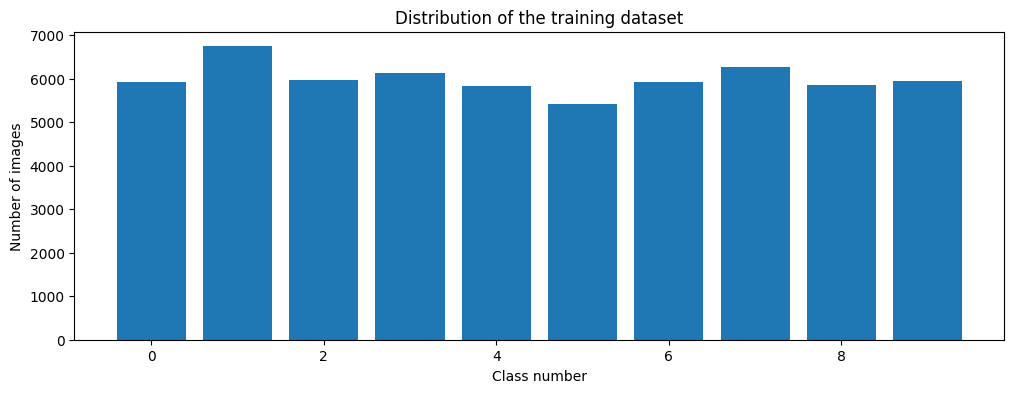

In [ ]:
print(num_of_samples)
plt.figure(figsize=(12, 4))
plt.bar(range(0, num_classes), num_of_samples)
plt.title("Distribution of the training dataset")
plt.xlabel("Class number")
plt.ylabel("Number of images")

In [ ]:
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

In [ ]:
X_train = X_train / 255
X_test = X_test / 255

In [ ]:
num_pixels = 784
X_train = X_train.reshape(X_train.shape[0], num_pixels)
X_test = X_test.reshape(X_test.shape[0], num_pixels)

In [ ]:
def create_model():
  model = Sequential()
  model.add(Dense(10, input_dim=num_pixels, activation='relu'))
  model.add(Dense(10, activation='relu'))
  model.add(Dense(num_classes, activation='softmax'))
  model.compile(Adam(learning_rate=0.01), loss='categorical_crossentropy', metrics=['accuracy'])
  return model

In [ ]:
model = create_model()
print(model.summary())

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_10 (Dense)                │ (None, 10)             │         7,850 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 10)             │           110 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,070 (31.52 KB)

 Trainable params: 8,070 (31.52 KB)

 Non-trainable params: 0 (0.00 B)

None


In [ ]:
history = model.fit(X_train, y_train, validation_split=0.1, epochs=10, batch_size=200, verbose=1, shuffle=1)

Epoch 1/10
270/270 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8024 - loss: 0.6313 - val_accuracy: 0.9245 - val_loss: 0.2544
Epoch 2/10
270/270 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9114 - loss: 0.3032 - val_accuracy: 0.9260 - val_loss: 0.2480
Epoch 3/10
270/270 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9181 - loss: 0.2806 - val_accuracy: 0.9358 - val_loss: 0.2249
Epoch 4/10
270/270 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9226 - loss: 0.2660 - val_accuracy: 0.9370 - val_loss: 0.2211
Epoch 5/10
270/270 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9262 - loss: 0.2536 - val_accuracy: 0.9372 - val_loss: 0.2151
Epoch 6/10
270/270 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9278 - loss: 0.2464 - val_accuracy: 0.9368 - val_loss: 0.2151
Epoch 7/10
270/270 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9286 - loss: 0.2453 - val_accuracy: 0.9372 - val_loss: 0.2147
Epoch 8/10
270/270 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9295 - loss: 0.2388 - val_accuracy: 0.

Text(0.5, 0, 'epoch')

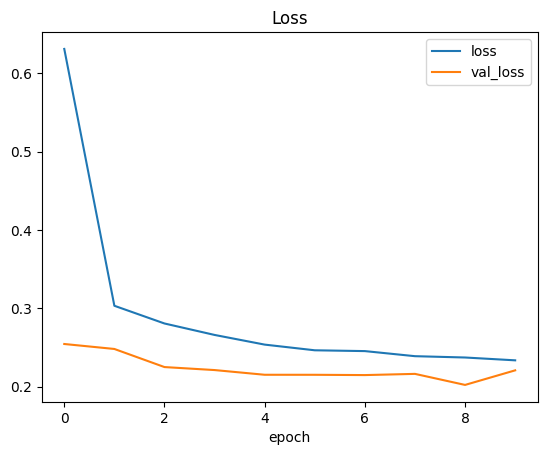

In [ ]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.legend(['loss', 'val_loss'])
plt.title('Loss')
plt.xlabel('epoch')

Text(0.5, 0, 'epoch')

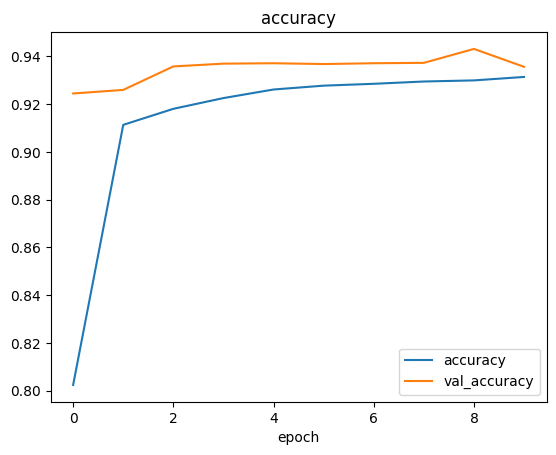

In [ ]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.legend(['accuracy', 'val_accuracy'])
plt.title('accuracy')
plt.xlabel('epoch')

In [ ]:
score = model.evaluate(X_test, y_test, verbose=0)
print('Test Score:', score[0])
print('Test Accuracy:', score[1])

Test Score: 0.2605181038379669
Test Accuracy: 0.9257000088691711


In [ ]:
import requests
from PIL import Image

url = 'https://colah.github.io/posts/2014-10-Visualizing-MNIST/img/mnist_pca/MNIST-p1815-4.png'

response = requests.get(url, stream=True)
img = Image.open(response.raw)
plt.imshow(img)

NameError: name 'plt' is not defined

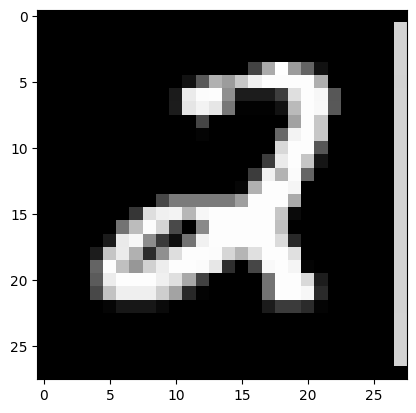

In [ ]:
import cv2

img_array = np.asarray(img)
resized = cv2.resize(img_array, (28, 28))
gray_scale = cv2.cvtColor(resized, cv2.COLOR_BGR2GRAY)
final_img = cv2.bitwise_not(gray_scale)
plt.imshow(final_img, cmap=plt.get_cmap('gray'))

In [ ]:
final_img = final_img / 255
final_img = final_img.reshape(1, 784)

In [ ]:
predictions = model.predict(final_img)
prediction = np.argmax(predictions, axis=1)
print("Predicted Digit:", str(prediction))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
Predicted Digit: [2]
